In [1]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys
from SiEPIC.utils import klive

# Generic Imports
import os
import pya
from pya import *
import numpy as np
import pandas as pd
from SiEPIC.utils import klive
from SiEPIC.scripts import connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC._globals import Python_Env
from SiEPIC.utils.layout import new_layout
import sys
import openpyxl

KLayout SiEPIC-Tools version 0.5.31
SiEPIC-Tools is up to date (0.5.31 vs 0.5.31).
Version check, time: 0.13339805603027344 seconds


In [2]:

if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "Shallow_Etch_BTO_PDK","klayout"))

    # Now try importing the PDK
    import Shallow_Etch_BTO



SiEPIC-Shallow_Etch_BTO-PDK Python module: Shallow_Etch_BTO_PDK, KLayout technology: Shallow_Etch_BTO
SiEPIC-Shallow_Etch_BTO-PDK Python module: pymacros
 - Technology path: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO
 - PCell folder path: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO\python\pcells_Shallow_Etch_BTO
 - PCell module name: pcells_Shallow_Etch_BTO
 - PCell init file: D:\Github\Shallow_Etch_BTO_PDK\klayout\Shallow_Etch_BTO\python\pcells_Shallow_Etch_BTO\__init__.py
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_CustomTaper
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_dc_halfring_straight
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_spiral_paperclip
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_taper
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_ShEtch_VarBend
 - imported PCell: pcells_Shallow_Etch_BTO.BTO_Universal_GC
 - imported PCell: pcells_Shallow_Etch_BTO.euler_bend_180
 - imported PCell: pcells_Shallow_Etch_BTO.S

In [3]:
tech_name = 'Shallow_Etch_BTO'  # Can change this
gclib_name = 'Shallow_Etch_BTO'
lib_name = 'Shallow_Etch_BTO'

top_cell_name = 'TT'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_bto'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_bto'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip


In [4]:
def GDS_Export(topcell,cellname):
    # Export for fabrication, removing PCells
    path = r"D:\Github\SiEPIC-Klayout-in-VSCode\floorplan_btomrr\gds_in"

    file_out = export_layout(topcell, path, cellname, relative_path = '', format='gds', screenshot=True)

    # Display the layout in KLayout, using KLayout Package "klive", which needs to be installed in the KLayout Application
    if Python_Env == 'Script':
        klive.show(file_out, technology=tech_name)

    print('\n COMPLETED \n')

In [5]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(top_cell_name)
_top_cell.write(layout_file) #save the layout to a GDS file

In [6]:
"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(top_cell_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

Could not connect to klive server. Is klayout open and klive plugin installed?


In [7]:
top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell

(4000.0, 4000.0, 4000000, 4000000)

Could not connect to klive server. Is klayout open and klive plugin installed?


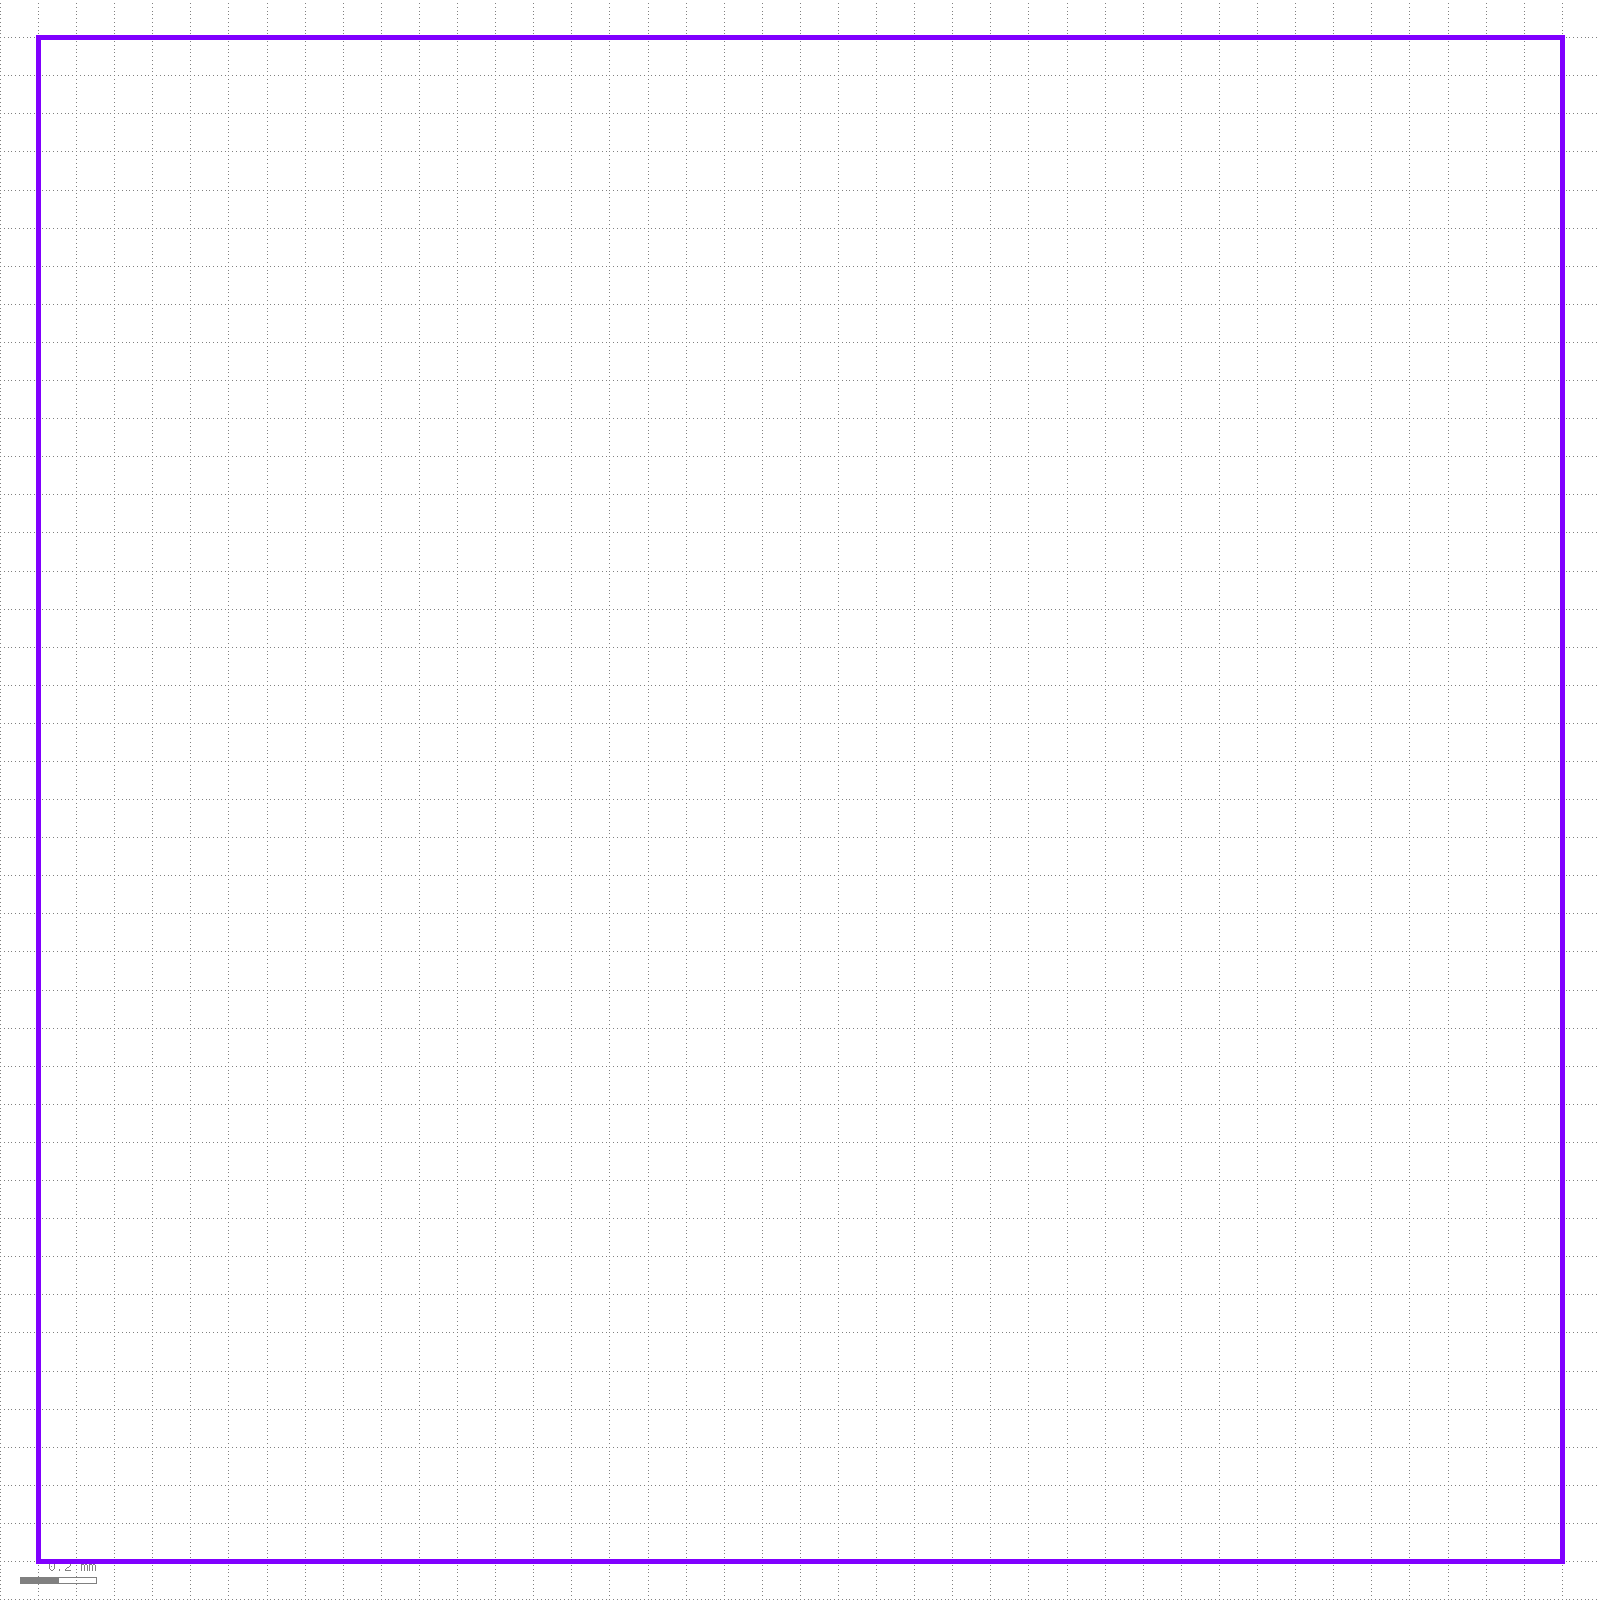

In [8]:
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [9]:
# ============================================================
# Global/default GC settings
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS = {
    "gc_cell_name": "BTO_ShEtch_GC_1550",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}
WG_SETTINGS = {
    "wg_type": "Low-loss Bend Waveguide, w=1.2um r=100um",
}
device_prefix = "opt_in_TE_1550_device_JSong"

margin_x = 250

In [10]:
def GC_placement(x,y,ParentCell,angle=0):
    global GC_SETTINGS
    
    GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])

    if angle == 0:
        t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    else:
        t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
    return GC_pcell, GC_inst

In [11]:
def Ring(x,y,ParentCell,r=100,w=1.2,g=0.2,Lc=0,angle=45):
    Ring_cell = ly.create_cell("ringtop")
    
    Ring_pcell1 = ly.create_cell("BTO_ShEtch_dc_halfring_straight",tech_name,{"r": r,"w": w,"g": g,"Lc": Lc,"AddDrop":True})
    t = pya.Trans(pya.Trans.R0, 0, 0)
    Ring_inst1 = Ring_cell.insert(pya.CellInstArray(Ring_pcell1.cell_index(), t))
    
    Ring_pcell2 = ly.create_cell("BTO_ShEtch_dc_halfring_straight",tech_name,{"r": r,"w": w,"g": g,"Lc": Lc,"AddDrop":False})
    t = pya.Trans(pya.Trans.R180, 0, + Ring_inst1.bbox().bottom + Ring_pcell2.bbox().bottom + Ring_inst1.bbox().height()+ Ring_pcell2.bbox().height() - 0.02e3)
    Ring_inst2 = Ring_cell.insert(pya.CellInstArray(Ring_pcell2.cell_index(), t))
    
    t = pya.Trans(pya.Trans.R90, x, y)
    Ring_inst = ParentCell.insert(pya.CellInstArray(Ring_cell.cell_index(), t))
    return Ring_pcell1, Ring_inst1

for blk in range(1):
    #====== MAIN ======
    if __name__ == "__main__":

        # Create a new layout for the chip floor plan
        cellname = f"Ring_Block{blk+1}"
        
        topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)
        
        MZIFP = pya.Box(0,0,2500e3,2500e3)
        topcell.shapes(ly.layer(ly.TECHNOLOGY['FloorPlan'])).insert(MZIFP)

        # instantiate the cell
        library = tech_name+ "test_lib"
        
        wg = "Low-loss Bend Waveguide, w=1.2um r=100um"
        #wg = "GC Loopback Bend Waveguide, w=1.2um r=60um"
        
        rads = [50,80]
        gaps = [0.1,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55]
        
        x0 = 5e3; y0 = 5e3
        x = x0
        for x_itr in range(12):
            y = y0
            
            for y_itr in range(5):
                
                if x_itr in [0,1,4,5,8,9]:
                    rad = 50
                elif x_itr in [2,3,6,7,10,11]:
                    rad = 80
                
                num = x_itr*5 + y_itr
                [GC1_pcell,GC1_inst] = GC_placement(x,y,topcell)
                [GC2_pcell,GC2_inst] = GC_placement(x,y + 3*127e3,topcell)
                wvl = 1550
                label = pya.Text(f"opt_in_TE_1550_device_Ring{num}rad{rad}gap{gaps[y_itr + 5*(x_itr%2)]}GC{wvl}",pya.Trans(pya.Trans.R0, x + GC2_pcell.bbox().width(), y + 3*127e3 + GC2_pcell.bbox().height()/2))
                topcell.shapes(ly.layer(ly.TECHNOLOGY['Text'])).insert(label)
                [Ring_pcell,Ring_inst] = Ring(x + GC2_pcell.bbox().width() + 110e3,y + 1.5*127e3 + GC2_pcell.bbox().height()/2,topcell,r=rad,g=gaps[y_itr + 5*(x_itr%2)])
                connect_pins_with_waveguide(Ring_inst,'opt1',GC1_inst,'opt1',waveguide_type=wg)
                connect_pins_with_waveguide(Ring_inst,'opt3',GC2_inst,'opt1',waveguide_type=wg)
                y += 127e3*3 + 125e3
            x += 209e3

        zoom_out(MZIFP)
        
        GDS_Export(topcell,cellname)

Could not connect to klive server. Is klayout open and klive plugin installed?

 COMPLETED 



In [12]:
def ybranch(x,y,Parentcell):
    pcell = ly.create_cell("BTO_ShEtch_ybranch",tech_name)
    t = pya.Trans(pya.Trans.R0, x - pcell.bbox().left, y)
    inst = Parentcell.insert(pya.CellInstArray(pcell.cell_index(), t))
    return pcell, inst

# def VarBend(x,y,Parentcell):
#     pcell = ly.create_cell("BTO_ShEtch_VarBend",tech)
#     t = pya.Trans(pya.Trans.R0, x - pcell.bbox().left, y)
#     inst = Parentcell.insert(pya.CellInstArray(pcell.cell_index(), t))
#     return pcell, inst

def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1.2,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
    VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
    return VB_pcell, VB_inst

def MZI(x,y,Parentcell,dL,num=0,wvl=1550,angle_deg=45):
    MZIcell2 = ly.create_cell("MZIcell2")
    
    MZIcell = ly.create_cell("MZIcell")
    dL = dL - 15e3
    angle = 0
    [GC1_pcell, GC1_inst] = GC_placement(x,y,Parentcell,angle)
    y+=2*127e3
    [GC2_pcell, GC2_inst] = GC_placement(x,y,Parentcell,angle)
    label = pya.Text(f"opt_in_TE_1550_device_MZI{num}wvl{wvl}",pya.Trans(pya.Trans.R0, x + GC2_pcell.bbox().width(), y + GC2_pcell.bbox().height()/2))
    Parentcell.shapes(ly.layer(ly.TECHNOLOGY['Text'])).insert(label)
    
    x += GC1_pcell.bbox().width()/2 - 0.01e3
    y += GC1_pcell.bbox().height()/2 - 9.2e3/2
    xgc = x; ygc = x

    y -= 2*127e3
    x += 100e3
    
    # mzi cell
    
    x_mzi=0
    y_mzi=0
    
    angle1 = -90 - (angle_deg)
    angle2 = -90
    
    [VB_pcell1,VB_inst1] = VarBend(0,0,MZIcell,angle1,angle2)
    [VB_pcell2,VB_inst2] = VarBend(0,2*127e3,MZIcell,angle1,angle2)
    
    [YB1_pcell,YB1_inst] = ybranch(x_mzi,y_mzi,MZIcell)
    
    y_mzi += 127e3*2
    [YB2_pcell,YB2_inst] = ybranch(x_mzi,y_mzi,MZIcell)
    
    y_mzi -= GC1_pcell.bbox().height()/2
    x_mzi -= GC1_pcell.bbox().width() -0.01e3

    wg_l = 10
    x_mzi += GC1_pcell.bbox().width() + YB2_pcell.bbox().width() + dL/2 + 100e3
    y_mzi += -127e3*2 - wg_l*1e3/2 + 127e3 + GC1_pcell.bbox().height()/2
    
    WG_pcell = ly.create_cell("Waveguide",tech_name,{"path": pya.DPath([pya.DPoint(0,0), pya.DPoint(0,wg_l)],1.2), "waveguide_type": wg})
    t = pya.Trans(pya.Trans.R0, x_mzi, y_mzi)
    WG_inst = MZIcell.insert(pya.CellInstArray(WG_pcell.cell_index(), t))
    
        # === Pad and Electrode Dimensions ===
    pad_size = 210e3  # square pad (width and height)
    elec_len = 420e3
    electrode_width = 5e3
    electrode_spacing = 1.2e3 + 2*8e3
    bridge_length = 252.3e3/2 - (electrode_spacing - 9.2e3)/2 - electrode_width - pad_size/2
    electrode_to_pad_offset = pad_size/2 + electrode_width/2 + bridge_length
    vertical_spacing = 2*bridge_length + 2* electrode_width + electrode_spacing
    buf = 4e3
    
    Pad_spacing = bridge_length*2 + electrode_width*2 + electrode_spacing
    
    # === Insert Etched area ===
    Pad_width = 252.3e3 - (electrode_spacing - 9.2e3) - electrode_width*2 - buf*2
    y_mzi += wg_l*1e3/2; x_mzi -= (dL/3.5 + 14e3) + 25e3
    PadArea = pya.Box(x_mzi-Pad_width/2, y_mzi-Pad_width/2, x_mzi+Pad_width/2,y_mzi+Pad_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["fast_exposure"])).insert(PadArea)
    
    y_mzi += pad_size + Pad_spacing
    PadArea = pya.Box(x_mzi-Pad_width/2, y_mzi-Pad_width/2, x_mzi+Pad_width/2,y_mzi+Pad_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["fast_exposure"])).insert(PadArea)
    y_mzi -= pad_size + Pad_spacing
    
    y_mzi -= pad_size + Pad_spacing
    PadArea = pya.Box(x_mzi-Pad_width/2, y_mzi-Pad_width/2, x_mzi+Pad_width/2,y_mzi+Pad_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["fast_exposure"])).insert(PadArea)
    y_mzi += pad_size + Pad_spacing
    
    # === Insert Pads ===
    # Pad center
    pad_y_center = y_mzi
    pad_x_center = x_mzi

    # Middle pad
    middle_pad = pya.Box(pad_x_center - pad_size/2, pad_y_center - pad_size/2,
                    pad_x_center + pad_size/2, pad_y_center + pad_size/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(middle_pad)
    # Top pad
    pad_y_center += pad_size + vertical_spacing
    top_pad = pya.Box(pad_x_center - pad_size/2, pad_y_center - pad_size/2,
                        pad_x_center + pad_size/2, pad_y_center + pad_size/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(top_pad)
    # Bottom pad
    pad_y_center -= 2 * (pad_size + vertical_spacing)
    bottom_pad = pya.Box(pad_x_center - pad_size/2, pad_y_center - pad_size/2,
                        pad_x_center + pad_size/2, pad_y_center + pad_size/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(bottom_pad)

    # Restore y_mzi to original position + pad offset
    y_mzi = pad_y_center + pad_size + vertical_spacing

    # === Insert Top Electrodes (2 horizontal, 2 vertical bridges) ===
    y_mzi += electrode_to_pad_offset

    # First horizontal electrode
    electrode_top1 = pya.Box(pad_x_center - elec_len/2, y_mzi - electrode_width/2,
                            pad_x_center + elec_len/2, y_mzi + electrode_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(electrode_top1)

    # Second horizontal electrode
    y_mzi += electrode_spacing + electrode_width
    electrode_top2 = pya.Box(pad_x_center - elec_len/2, y_mzi - electrode_width/2,
                            pad_x_center + elec_len/2, y_mzi + electrode_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(electrode_top2)

    electrode_top_clad = pya.Box(pad_x_center - elec_len/2 - buf, y_mzi - electrode_width*3/2 - buf - electrode_spacing,
                            pad_x_center + elec_len/2 + buf, y_mzi + electrode_width/2 + buf)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["BTO_clad"])).insert(electrode_top_clad)

    # Store center for later
    y_center_top = y_mzi

    # First vertical bridge
    y_mzi += (bridge_length)/2 + electrode_width/2
    y_center_top = y_mzi
    bridge_top1 = pya.Box(pad_x_center - electrode_width/2, y_mzi - bridge_length/2,
                        pad_x_center + electrode_width/2, y_mzi + bridge_length/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(bridge_top1)

    # Second vertical bridge
    y_mzi -= 2 * electrode_width + electrode_spacing + bridge_length
    bridge_top2 = pya.Box(pad_x_center - electrode_width/2, y_mzi - bridge_length/2,
                        pad_x_center + electrode_width/2, y_mzi + bridge_length/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(bridge_top2)

    # === Insert Bottom Electrodes (mirrored layout) ===
    y_mzi = y_center_top
    y_mzi -= 2.5*electrode_width + 2.5*bridge_length + pad_size + electrode_spacing

    # First bottom horizontal electrode
    electrode_bot1 = pya.Box(pad_x_center - elec_len/2, y_mzi - electrode_width/2,
                            pad_x_center + elec_len/2, y_mzi + electrode_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(electrode_bot1)

    # Second bottom horizontal electrode
    y_mzi -= electrode_spacing + electrode_width
    electrode_bot2 = pya.Box(pad_x_center - elec_len/2, y_mzi - electrode_width/2,
                            pad_x_center + elec_len/2, y_mzi + electrode_width/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(electrode_bot2)
    
    electrode_bot_clad = pya.Box(pad_x_center - elec_len/2 - buf, y_mzi - electrode_width/2 - buf,
                            pad_x_center + elec_len/2 + buf, y_mzi + electrode_width*3/2 + buf + electrode_spacing)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["BTO_clad"])).insert(electrode_bot_clad)

    # First bottom vertical bridge
    y_mzi -= bridge_length/2 + electrode_width/2
    bridge_bot1 = pya.Box(pad_x_center - electrode_width/2, y_mzi - bridge_length/2,
                        pad_x_center + electrode_width/2, y_mzi + bridge_length/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(bridge_bot1)

    # Second bottom vertical bridge
    y_mzi += 2 * electrode_width + electrode_spacing + bridge_length
    bridge_bot2 = pya.Box(pad_x_center - electrode_width/2, y_mzi - bridge_length/2,
                        pad_x_center + electrode_width/2, y_mzi + bridge_length/2)
    MZIcell.shapes(ly.layer(ly.TECHNOLOGY["Gold"])).insert(bridge_bot2)

    
    connect_pins_with_waveguide(YB1_inst,'opt2',YB2_inst,'opt3',waveguide_type=wg)
    connect_pins_with_waveguide(YB1_inst,'opt3',WG_inst,'opt1',waveguide_type=wg)
    connect_pins_with_waveguide(WG_inst,'opt2',YB2_inst,'opt2',waveguide_type=wg)

    #angle_deg = 60; 
    r = 100e3
    #rotation = pya.DCplxTrans(1.0, angle_deg, False, xgc + r*np.sin(angle_deg*np.pi/180) + 300e3, ygc + r*np.cos(angle_deg*np.pi/180) + 17.64e3)
    rotation = pya.DCplxTrans(1.0, angle_deg, False, r*np.sin(angle_deg*np.pi/180), r-r*np.cos(angle_deg*np.pi/180))
    print()
    
    MZI_inst1 = MZIcell2.insert(pya.CellInstArray(MZIcell.cell_index(), rotation))
    from SiEPIC.utils.layout import make_pin
    make_pin(MZIcell2,"pin3",pya.DPoint(0.011,0),1.2,ly.TECHNOLOGY['PinRec'],180)
    make_pin(MZIcell2,"pin4",pya.DPoint(0.011-2*127*np.sin(angle_deg*np.pi/180),2*127*np.cos(angle_deg*np.pi/180)),1.2,ly.TECHNOLOGY['PinRec'],180)
    
    if angle_deg < 60:
        t = pya.Trans(pya.Trans.R0, x + 2*127e3*np.sin(np.pi*angle_deg/180) + 130e3, y + 9.2e3/2)
    else:
        t = pya.Trans(pya.Trans.R0, x + 2*127e3*np.sin(np.pi*angle_deg/180) + 130e3, y + 127e3*np.sin(np.pi*angle_deg/180) + 9.2e3/2)
    MZI_inst2 = Parentcell.insert(pya.CellInstArray(MZIcell2.cell_index(), t))
    
    connect_pins_with_waveguide(MZI_inst2,'pin3',GC1_inst,'opt1',waveguide_type=wg)
    connect_pins_with_waveguide(MZI_inst2,'pin4',GC2_inst,'opt1',waveguide_type=wg)
    
    return x,y,MZIcell2

for blk in range(1):
    #====== MAIN ======
    if __name__ == "__main__":

        # Create a new layout for the chip floor plan
        cellname = "MZI_Block"
        
        topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)
        
        MZIFP = pya.Box(0,0,3100e3,2650e3)
        #MZIFP = pya.Box(0,0,2000e3,1800e3)
        topcell.shapes(ly.layer(ly.TECHNOLOGY['SEM'])).insert(MZIFP)

        # instantiate the cell
        library = tech_name + "test_lib"
        
        wg = "Low-loss Bend Waveguide, w=1.2um r=100um"
        dL = 1000e3
        
        x0 = 10e3; y0 = 250e3 + 12.564e3
        x = x0
        anglestp = 0
        angles = [0,20,45,60]
        for x_itr in range(3):
            y = y0
            if x_itr == 1:
                y -= 170e3
            elif x_itr == 2:
                y -= 220e3
            for y_itr in range(3):
                num = x_itr*4 + y_itr
                #[xf,yf,MZI_inst] = MZI(x,y,topcell,dL,num=num,wvl=1550,angle_deg=angles[x_itr*2+y_itr])
                [xf,yf,MZI_inst] = MZI(x,y,topcell,dL,num=num,wvl=1550,angle_deg=anglestp)
                y += 127e3*2 + 580e3
                anglestp += 11.25
            x += 200e3 + MZI_inst.bbox().width()
            

        zoom_out(MZIFP)
        
        GDS_Export(topcell,cellname)










klive didn't send data, closing

 COMPLETED 



In [13]:
# Single-pass racetrack ring modulator
#
# Geometry:
#   - Lc=0 for both half-rings (coupler at bend)
#   - top_half: AddDrop=True has built-in bus waveguide (pin1/pin3)
#   - bot_half: AddDrop=False closes the ring
#   - Two explicit straight waveguides connect the two half-rings
#   - Positive angle_deg rotates clockwise
#   - Grating coupler spacing is fixed to 127*2 um
def GC_placement(x,y,ParentCell,angle=0):
    global GC_SETTINGS
    
    GC_pcell = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])

    if angle == 0:
        t = pya.Trans(pya.Trans.R0, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    else:
        t = pya.DCplxTrans(1.0, angle, False, x + GC_pcell.bbox().width(), y - GC_pcell.bbox().bottom)
    GC_inst = ParentCell.insert(pya.CellInstArray(GC_pcell.cell_index(), t))
    return GC_pcell, GC_inst
def place_VarBEnd(inst4connect,instpin,Bendpin,angle1=-90,angle2=-45):
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1.2,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    inst_VarBend = connect_cell(inst4connect, instpin, VB_pcell , Bendpin)
    return VB_pcell, inst_VarBend

def VarBend(x,y,ParentCell,angle1=-90,angle2=-45):
    
    VB_pcell = ly.create_cell("BTO_ShEtch_VarBend",tech_name,{
            "wg_width": 1.2,
            "bend_r": 100,
            "angle1": angle1,
            "angle2": angle2,      
        })
    t = pya.Trans(pya.Trans.R0, x+0.01e3, y - VB_pcell.bbox().bottom - 9.2e3/2)
    VB_inst = ParentCell.insert(pya.CellInstArray(VB_pcell.cell_index(), t))
    return VB_pcell, VB_inst

def SinglePassRacetrackMod(
    x,
    y,
    ParentCell,
    straight_len_um=100,
    gap_um=0.2,
    radius_um=80,
    wg_width_um=1.2,
    angle_deg=45,
    electrode_width_um=5,
    electrode_gap_um=6,
    electrode_clearance_um=2,
    waveguide_type=None,
    electrode_size_um = 210,
):
    from SiEPIC.utils.layout import make_pin

    dbu = ly.dbu
    if waveguide_type is None:
        waveguide_type = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

    wg_half = to_itype(wg_width_um / 2+4, dbu)
    wg_wdith = to_itype(wg_width_um, dbu)
    e_w = to_itype(electrode_width_um, dbu)
    e_gap = to_itype(electrode_gap_um, dbu)
    e_clr = to_itype(electrode_clearance_um, dbu)
    straight = to_itype(straight_len_um, dbu)
    electrode_gap = to_itype(electrode_gap_um, dbu)
    electrode_size = to_itype(electrode_size_um, dbu)

    
    gap_tag = str(gap_um).replace(".", "p")
    base_tag = f"R{int(radius_um)}_G{gap_tag}_L{int(straight_len_um)}_A{int(angle_deg)}"

    # 1) Half-rings
    rt_core = ly.create_cell(f"SP_RacetrackCore_{base_tag}")
    rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}_2")

    # angle = 0
    # [GC1_pcell, GC1_inst] = GC_placement(x,y,ParentCell,angle)
    # y+=2*127e3
    # [GC2_pcell, GC2_inst] = GC_placement(x,y,ParentCell,angle)
    # label = pya.Text(f"opt_in_TE_1550_device_RacetrackRing{base_tag}",pya.Trans(pya.Trans.R0, x + GC2_pcell.bbox().width(), y + GC2_pcell.bbox().height()/2))
    # ParentCell.shapes(ly.layer(ly.TECHNOLOGY['Text'])).insert(label)

    # x += GC1_pcell.bbox().width()/2 - 0.01e3
    # y += GC1_pcell.bbox().height()/2 - 9.2e3/2
    # xgc = x; ygc = x

    gc_distance = 3*127e3
    # y -= gc_distance
    # x += 100e3
    
    # Add bend
    x_ring = 0
    y_ring = 0
        

    top_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": True},
    )
    top_inst = rt_core.insert(pya.CellInstArray(top_half.cell_index(), pya.Trans(pya.Trans.R0, 0, 0)))

    bot_half = ly.create_cell(
        "BTO_ShEtch_dc_halfring_straight",
        tech_name,
        {"r": radius_um, "w": wg_width_um, "g": gap_um, "Lc": 0, "AddDrop": False},
    )

    t_bot = pya.Trans(
        pya.Trans.R180,
        0,
        top_inst.bbox().top + to_itype(wg_width_um, dbu) + straight + bot_half.bbox().height() - to_itype(wg_width_um, dbu),
    )
    bot_inst = rt_core.insert(pya.CellInstArray(bot_half.cell_index(), t_bot))

    # 2) Explicit straight waveguides, positioned by waveguide centerlines
    connect_pins_with_waveguide(top_inst,'pin2',bot_inst,'pin4',waveguide_type=wg)
    connect_pins_with_waveguide(top_inst,'pin4',bot_inst,'pin2',waveguide_type=wg)


    # ring_x_left = top_inst.bbox().left + wg_half
    # ring_x_right = top_inst.bbox().right - wg_half

    # # # Vertical centers where straight sections should connect
    # y_upper_center = top_inst.bbox().top + wg_half
    # y_lower_center = bot_inst.bbox().bottom - wg_half

    # y_start = min(y_upper_center, y_lower_center)
    # y_end = max(y_upper_center, y_lower_center)
    # straight_len_actual_um = (y_end - y_start) * dbu

    # for cx in (ring_x_left, ring_x_right):
    #     wg_straight = ly.create_cell(
    #         "Waveguide",
    #         tech_name,
    #         {
    #             "path": pya.DPath([pya.DPoint(0, 0), pya.DPoint(0, straight_len_actual_um)], wg_width_um),
    #             "waveguide_type": waveguide_type,
    #         },
    #     )
    #     rt_core.insert(
    #         pya.CellInstArray(
    #             wg_straight.cell_index(),
    #             pya.Trans(pya.Trans.R0, cx - wg_half, y_start),
    #         )
    #     )

    # 3) Electrodes (3 strips)
    ring_x_left = top_inst.bbox().left + wg_half
    ring_x_right = top_inst.bbox().right - wg_half

    y_upper_center = bot_inst.bbox().bottom + 0.1
    y_lower_center = top_inst.bbox().top - 0.1

    y_start = min(y_upper_center, y_lower_center)
    y_end = max(y_upper_center, y_lower_center)
    straight_len_actual_um = (y_end - y_start) * dbu

    metal_layer = ly.layer(ly.TECHNOLOGY["Gold"])
    clad_layer = ly.layer(ly.TECHNOLOGY["BTO_clad"]) if "BTO_clad" in ly.TECHNOLOGY else None

    # print(f"wg_half: {wg_half}, y_upper_center: {y_upper_center}, y_lower_center: {y_lower_center}, straight_len_actual_um: {straight_len_actual_um}")
    xl_e = ring_x_left - wg_half
    xr_e = ring_x_right + wg_half

    y_upper = y_upper_center
    y_lower = y_lower_center

    # Electrode 1: at the middle, centered between the two waveguides
    rt_core.shapes(metal_layer).insert(
        pya.Box(xl_e + wg_half + wg_wdith/2+electrode_gap/2, y_upper, xr_e - wg_half-electrode_gap/2, y_lower)
    )
    # Electrodes 2 and 3: above and below the waveguides, separated by e_gap from the center electrode and wg edge
    rt_core.shapes(metal_layer).insert(
        pya.Box(xl_e + wg_half-wg_wdith/2-electrode_gap/2, y_upper, xl_e-electrode_size, y_lower)
    )
    rt_core.shapes(metal_layer).insert(
        pya.Box(xr_e - wg_half+wg_wdith/2+electrode_gap/2, y_upper, xr_e+electrode_size, y_lower)
    )

    y_cen_top = y_upper - wg_half - e_gap
    y_cen_bot = y_lower + wg_half + e_gap
    
    # if y_cen_top > y_cen_bot:
    #     rt_core.shapes(metal_layer).insert(pya.Box(xl_e, y_cen_bot, xr_e, y_cen_top))

    if clad_layer is not None:
        rt_core.shapes(clad_layer).insert(
            pya.Box(
                # xl_e - e_clr,
                xl_e-electrode_size  - e_clr,
                y_lower - wg_half - e_gap - e_w - e_clr,
                # xr_e + e_clr,
                xr_e+electrode_size + e_clr,
                y_upper + wg_half + e_gap + e_w + e_clr,
            )
        )

    angle1 = (0)
    angle2 = angle_deg
    
    # [VB_pcell1,VB_inst1] = VarBend(xl_e-10*dbu,y_lower,rt_core,angle1,angle2)
    # [VB_pcell2,VB_inst2] = VarBend(xr_e+10*dbu,y_lower,rt_core,-angle1,-angle2)

    # connect_pins_with_waveguide(top_inst,'pin1',VB_inst1,'pin2',waveguide_type=wg)
    # connect_pins_with_waveguide(top_inst,'pin3',VB_inst2,'pin2',waveguide_type=wg)

    angle1 = (0)
    angle2 = angle_deg

    [VB_pcell1,VB_inst1] = place_VarBEnd(inst4connect = top_inst, instpin='pin1', Bendpin='pin1', angle1=angle1+90, angle2=angle2+90)
    if angle_deg < 46:
        # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+0, angle2=-2*angle2-90)
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    else:
        # [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1+180+90, angle2=-angle2+270)
        [VB_pcell2,VB_inst2] = place_VarBEnd(inst4connect = top_inst, instpin='pin3', Bendpin='pin1', angle1=angle1, angle2=angle2-180)

    # 4) Wrapper rotation: clockwise for positive angle_deg
    # rt_wrapper = ly.create_cell(f"SP_RacetrackWrap_{base_tag}")
    rot = pya.DCplxTrans(1.0, -angle_deg, False, 0, 0)
    core_inst = rt_wrapper.insert(pya.CellInstArray(rt_core.cell_index(), rot))

    # Avoid ambiguous global pin lookup in rt_core; use the known top half pins and transform.
    pinup_local = VB_inst1.find_pin("pin2").center.to_dtype(dbu)
    pindw_local = VB_inst2.find_pin("pin2").center.to_dtype(dbu)
    pin1_pt = rot * pinup_local 
    pin3_pt = rot * pindw_local

    make_pin(rt_wrapper, "pin_in", pin1_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)
    make_pin(rt_wrapper, "pin_out", pin3_pt, 0.02*dbu, ly.TECHNOLOGY["PinRec"], 180)

    # 5) Place wrapper and GCs
    # Choose vertical anchor: "pin_out" or "bottom"
    y_anchor_mode = "pin_out"
    if y_anchor_mode == "bottom":
        y_anchor_local = rt_wrapper.bbox().bottom
    else:
        y_anchor_local = to_itype(rt_wrapper.find_pin("pin_out").center.to_dtype(dbu).y, dbu)
    y_shift = y - y_anchor_local
    rt_inst = ParentCell.insert(pya.CellInstArray(rt_wrapper.cell_index(), pya.Trans(pya.Trans.R0, x, y_shift)))

    # Keep GC opt1 x-position fixed 200 um to the left of pin_in.
    pin_in_x = to_itype(rt_inst.find_pin("pin_in").center.to_dtype(dbu).x, dbu)
    pin_in_gc_dx = to_itype(200, dbu)

    gc_probe = ly.create_cell(GC_SETTINGS["gc_cell_name"], GC_SETTINGS["gc_library"])
    gc_pin_local_x = to_itype(gc_probe.find_pin("opt1").center.to_dtype(dbu).x, dbu)
    target_gc_opt1_x = pin_in_x - pin_in_gc_dx
    gc_x = target_gc_opt1_x - gc_probe.bbox().width() - gc_pin_local_x

    # Vertical spacing between the two GCs fixed at 127*2 um
    pin1_y = to_itype(rt_inst.find_pin("pin_in").center.to_dtype(dbu).y, dbu)
    pin3_y = to_itype(rt_inst.find_pin("pin_out").center.to_dtype(dbu).y-22.995, dbu)
    gc_pitch = to_itype(127 * 1, dbu)
    # y_mid = (pin1_y + pin3_y) // 2
    gc2_y = pin3_y
    gc1_y = pin3_y + gc_pitch

    _, gc1_inst = GC_placement(gc_x, gc1_y, ParentCell, angle=0)
    _, gc2_inst = GC_placement(gc_x, gc2_y, ParentCell, angle=0)

    connect_pins_with_waveguide(rt_inst, "pin_in", gc1_inst, "opt1", waveguide_type=waveguide_type)
    connect_pins_with_waveguide(rt_inst, "pin_out", gc2_inst, "opt1", waveguide_type=waveguide_type)

    return rt_wrapper, rt_inst, gc1_inst, gc2_inst


# ===== Example =====
cellname = "SP_RacetrackMod_Block"
topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

FP = pya.Box(0, 0, 3600e3, 2400e3)
topcell.shapes(ly.layer(ly.TECHNOLOGY["SEM"])).insert(FP)

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

# (radius_um, gap_um, straight_len_um, angle_deg)
params = [
    (60, 0.20, 100, 15),
    (80, 0.25, 120, 30),
    (100, 0.30, 160, 60),
    (120, 0.35, 200, 90),
]

x0 = 900e3
y0 = 800e3
dx = 800e3

x = x0
for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
    _, rt_inst, _, _ = SinglePassRacetrackMod(
        x=x,
        y=y0,
        ParentCell=topcell,
        straight_len_um=Lc_um,
        gap_um=gap_um,
        radius_um=rad_um,
        angle_deg=ang,
        electrode_gap_um=6.2,
        waveguide_type=wg,
    )
    label = pya.Text(
        f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
        pya.Trans(pya.Trans.R0, x - 230e3, y0 + rt_inst.bbox().height() // 2 + 120e3),
    )
    topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
    x += dx

zoom_out(FP)
GDS_Export(topcell, cellname)

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "open", "file": "D:\\Github\\SiEPIC-Klayout-in-VSCode\\floorplan_btomrr\\gds_in\\SP_RacetrackMod_Block.gds"}

 COMPLETED 



In [ ]:
# ===== Example =====
cellname = "SP_RacetrackMod_Block"
topcell, ly = new_layout(tech_name, cellname, GUI=True, overwrite=True)

x_max = 4000e3
margin_x = 500e3
y_max = 3000e3
FP = pya.Box(0, 0, x_max, y_max)
topcell.shapes(ly.layer(ly.TECHNOLOGY["FloorPlan"])).insert(FP)

wg = WG_SETTINGS["wg_type"] if "WG_SETTINGS" in globals() else "Low-loss Bend Waveguide, w=1.2um r=100um"

# (radius_um, gap_um, straight_len_um, angle_deg)
params = [
    (50, 0.22, 100, 90),
    (50, 0.22, 100, 67.5),
    (50, 0.22, 100, 45),
    (50, 0.22, 100, 45),
    
    (50, 0.33, 100, 90),
    (50, 0.22, 100, 67.5),
    (50, 0.33, 100, 45),
    (50, 0.33, 100, 45),

    (50, 0.44, 100, 90),
    (50, 0.22, 100, 67.5),
    (50, 0.44, 100, 45),
    (50, 0.44, 100, 45),

    (80, 0.43, 100, 90),
    (50, 0.22, 100, 67.5),
    (80, 0.43, 100, 45),
    (80, 0.43, 100, 45),

]

x0 = 500e3
y0 = 200e3
dx = 500e3

x = x0
for i, (rad_um, gap_um, Lc_um, ang) in enumerate(params):
    _, rt_inst, _, _ = SinglePassRacetrackMod(
        x=x,
        y=y0,
        ParentCell=topcell,
        straight_len_um=Lc_um,
        gap_um=gap_um,
        radius_um=rad_um,
        angle_deg=ang,
        electrode_gap_um=6.2,
        waveguide_type=wg,
    )
    label = pya.Text(
        f"opt_in_TE_1550_device_SPRT{i}_R{rad_um}_G{gap_um}_L{Lc_um}_A{ang}",
        pya.Trans(pya.Trans.R0, x - 230e3, y0 + rt_inst.bbox().height() // 2 + 120e3),
    )
    topcell.shapes(ly.layer(ly.TECHNOLOGY["Text"])).insert(label)
    pos_cell = rt_inst.bbox().right
    # x += dx+width_cell
    x = pos_cell + dx
    if x + rt_inst.bbox().width() * dbu > x_max - margin_x:
        x = x0
        y0 += rt_inst.bbox().height() + 50e3

zoom_out(FP)
GDS_Export(topcell, cellname)

Message from klive: {"version": "0.4.1", "klayout_version": "0.29.4", "type": "reload", "file": "D:\\Github\\SiEPIC-Klayout-in-VSCode\\floorplan_btomrr\\gds_in\\SP_RacetrackMod_Block.gds"}

 COMPLETED 



: 